## Experiments: Recurrent Layers

Tom <br>
October __, 2026

This notebook tests how the recurrent layers affect the CNN-LSTM. Each experiment changes one parameter from the base model and compares the result on the validation set.

### How to Use This Notebook

- Build and run the base model first. Every experiment is compared with it, so it already covers the base value.
- Change one parameter at a time. Everything else stays at the base model.
- Before running an experiment, fill in the values you are testing, your hypothesis, why you chose those values, and the source that informed them.
- Judge results on validation accuracy and macro F1 only. The test set is saved for the final model.
- Fill in each results table, then the observations, insights and conclusion.

### Setup

In [1]:
import os

# Hide GPUs so everyone trains and times on CPU.
# Must run before importing TensorFlow; restart the kernel if it already was.
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'

In [2]:
import copy as cp
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from IPython.display import display, HTML
from tensorflow.keras import Sequential
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, Callback
from tensorflow.keras.layers import Input, LSTM, GRU, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import f1_score

In [3]:
SEED = 8

np.random.seed(SEED)
tf.random.set_seed(SEED)

In [4]:
# Locations of the shared data (relative to this notebook)
DATA_ROOT    = '../DATA'
FEATURE_PATH = DATA_ROOT + '/features'
MODEL_ROOT   = './models'

# Split names used in the feature file names and as dictionary keys
TRAIN      = 'train'
VALIDATION = 'val'
TEST       = 'test'


def load_data(backbone='resnet50', size=224, frames=16):
    """
    Load the precomputed CNN features and the labels for every split.

    Parameters:
        backbone: 'resnet50' or 'mobilenetv2'
        size:     input resolution the features were extracted at (224 or 112)
        frames:   frames per clip to keep (32, 16 or 8)

    Each saved clip has 32 evenly spaced frames, so fewer frames are made by
    keeping every 2nd (16) or every 4th (8) frame.

    Output:
        features: dict of float32 arrays shaped (clips, frames, feature size)
        labels:   dict of integer class labels (0-7)
    """
    step = 32 // frames
    features = {}
    labels   = {}

    # labels come from the shared splits file so everyone uses the same split
    label_data = np.load(f"{DATA_ROOT}/splits.npz")

    for name in [TRAIN, VALIDATION, TEST]:
        # features are saved as float16 to save space, so cast back for training
        x = np.load(f"{FEATURE_PATH}/{backbone}_{size}_{name}.npy").astype('float32')
        features[name] = x[:, ::step]
        labels[name]   = label_data[f'y_{name}']

    return (features, labels)


# Base model data: ResNet50, 224 px, 16 frames per clip
X, y = load_data('resnet50', 224, 16)

# Collects one row per run so the results tables can be printed
reports = []

for name in [TRAIN, VALIDATION, TEST]:
    print(name, X[name].shape, y[name].shape)

train (552, 16, 2048) (552,)
val (151, 16, 2048) (151,)
test (263, 16, 2048) (263,)


In [5]:
def config_to_html(conf, ignore_name=True):
    html_str = ""
    for k, v in conf.items():
        if ignore_name and (k == 'Experiment Name' or k == 'Setting'):
            continue
        if not isinstance(v, (int, float, str, tuple, list)):
            v = v.__name__
        html_str += f'''<p><span style="display: inline-block; width:150px; text-align: right">{k}</span>: {v}</p>'''
        
    return html_str

def print_report(df):
    styled_df = (df.style.hide_index()
                 .set_properties(**{'text-align': 'center'})
                 .set_table_styles([
                     { 'selector': 'th', 'props': [('text-align', 'center'), ('font-weight', 'bold')] }
                 ])
                )
    
    display(HTML("<h4>Results</h4>"))
    display(styled_df)

class Line(object):
    def __init__(self, data, label):
        self.data = data
        self.label = label

class Lines(object):
    def __init__(self, title, lines, xlabel, ylabel):
        self._title = title
        self._lines = lines
        self._xlabel = xlabel
        self._ylable = ylabel

    def plot(self, ax):
        for line in self._lines:
            ax.plot(line.data, label=line.label)

        ax.set_xlabel(self._xlabel)
        ax.set_ylabel(self._ylable)
        ax.legend()

def plot_twins_multiple_line_chart(lines):
    _, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    for i in range(2):
        lines[i].plot(axes[i])

    plt.tight_layout()
    plt.show()
    

def plot_training_history(history):
    # plot accuracy
    # Training Accuracy
    train_acc = Line(history['accuracy'], 'Training Accuracy')
    # Validation Accuracy
    val_acc = Line(history['val_accuracy'], 'Validation Accuracy')
    acc_lines = Lines('Accuracy Trend',
                      lines=[train_acc, val_acc],
                      xlabel='Epoch',
                      ylabel='Accuracy')
    
    # plot loss
    # Training Loss
    train_loss = Line(history['loss'], 'Training Loss')
    # Validation Loss
    val_loss = Line(history['val_loss'], 'Validation Loss')
    loss_lines = Lines('Loss Trend',
                       lines=[train_loss, val_loss],
                       xlabel='Epoch',
                       ylabel='Loss')

    plot_twins_multiple_line_chart([acc_lines, loss_lines])

In [6]:
import time

class LatencyTracker(Callback):
    '''
        Keras callback that records how long each training epoch takes (in seconds).
    '''

    def on_train_begin(self, logs=None):
        # reset the counters at the start of every fit()
        self.epoch_times = []
        self.total_epochs = 0

    def on_epoch_begin(self, epoch, logs=None):
        # start the clock for this epoch
        self.epoch_start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        # stop the clock and store how long the epoch took
        duration = time.time() - self.epoch_start_time

        self.epoch_times.append(duration)
        self.total_epochs += 1

    @property
    def total_latency(self):
        # total training time across all epochs
        return sum(self.epoch_times)

In [7]:
def create_optimizer(params):
    '''
        Build the optimizer named in the settings dict
        (Adam is the base model's).
    '''
    if params['Optimizer'] == Adam:
        return Adam(learning_rate=params['Learning rate'])
    return None

def measure_prediction_latency(model, X_clips, n_clips=100):
    '''
        Average time (ms) to predict ONE clip, the way the live demo would.
        
        Note: this times the recurrent part only, because the CNN features
              are precomputed.
    '''
    clips = tf.constant(X_clips[:n_clips])
    # warm-up call so setup time isn't counted
    model(clips[:1], training=False) 

    start = time.time()
    for i in range(n_clips):
        # direct call with a batch of 1 = one clip
        model(clips[i:i + 1], training=False)

    return (time.time() - start) / n_clips * 1000


def run_experiment(params, X, y, verbose=0, print_all=True):
    '''
        Build, train and evaluate one CNN-LSTM run, then add a row to `reports`.
    
        params: settings dict (copy of baseline_config with one value changed)
        X, y:   feature and label dicts from load_data()
        
        Results are judged on the validation set only; the test set is saved
        for the final model.
    '''
    input_shape = X[TRAIN].shape[1:]   # (frames, feature size)
    
    # create model: recurrent layer -> dropout -> softmax output
    model = Sequential([
        Input(shape=input_shape),
        params['Recurrent layer'](params['Hidden units']),
        Dropout(params['Droupout rate']),
        Dense(params['Output'][0], activation=params['Output'][1])
    ])
    
    # compile model
    optimizer = create_optimizer(params)
    model.compile(
        optimizer=optimizer,
        loss = params['Loss'],
        metrics = params['Metrics']
    )
        
    model.summary()

    # early-stopping moniters the validation loss
    early_stopping = EarlyStopping(monitor=params['Moniter'],
                                   patience=params['patience'],
                                   restore_best_weights=params['restore best weights'])
    
    # checkpoint save the best model
    checkpoint = ModelCheckpoint(
        params['stored model name'],
        monitor=params['Moniter'],
        save_best_only=True
    )
    
    # latency-tracker calculates and records the duration per epoch
    latency_tracker = LatencyTracker()
    
    history = model.fit(X[TRAIN], y[TRAIN],
                        validation_data=(X[VALIDATION], y[VALIDATION]),
                        epochs = params['Epochs'],
                        batch_size = params['Batch size'],
                        callbacks = [early_stopping,
                                     checkpoint,
                                     latency_tracker],
                        verbose = verbose)
    
    # evaluate with testing data
    test_loss, test_accuracy = model.evaluate(X[TEST], y[TEST], verbose=verbose)
    
    # calculation for the report
    val_loss, val_accuracy   = model.evaluate(X[VALIDATION], y[VALIDATION], verbose=verbose)
    y_val_pred = np.argmax(model.predict(X[VALIDATION], verbose=verbose), axis=1)
    val_f1 = f1_score(y[VALIDATION], y_val_pred, average=params['F1 Average'])
    
    report = {
        'Val accuracy': val_accuracy,
        'Val macro F1': val_f1,
        'Test Accuracy': test_accuracy,
        'Test Loss': test_loss,
        'Epochs run': len(history.history),
        'Parameters': config_to_html(params),
        'Latency (ms)': measure_prediction_latency(model, X[VALIDATION], 1),
        'Train time (s)': latency_tracker.total_latency
    }
    
    report_ext = {
        'Run': params['Experiment Name'],
        'Setting': params['Setting']
    }
    report_ext.update(report)
    reports.append(report_ext)
    
    if print_all:
        print_report(pd.DataFrame(reports))
    else:
        print_report(pd.DataFrame([report]))
        
    plot_training_history(history.history)

### Base Model

| Parameter | Base model |
|---|---|
| Backbone | ResNet50 (frozen, ImageNet weights) |
| Input resolution | 224 px |
| Frames per clip | 16 |
| Recurrent layer type | LSTM |
| Hidden units | 256 |
| Number of recurrent layers | 1 |
| Dropout placement | After the LSTM |
| Dropout rate | 0.5 |
| Output | Dense(8, softmax) |
| Optimizer | Adam |
| Learning rate | 0.001 |
| Loss | Sparse categorical cross-entropy |
| Batch size | 32 |
| Epochs | Up to 100, early stopping on val loss (patience 8, restore best weights) |
| Seed | 8 |

In [8]:
baseline_config = {}
baseline_config['Experiment Name']     = "base"
baseline_config['Setting'] = "-"

baseline_config['Recurrent layer'] = LSTM
baseline_config['Hidden units']    = 256
baseline_config['Droupout rate']   = 0.5
baseline_config['Output']          = (8, "softmax")
baseline_config['Optimizer']       = Adam
baseline_config['Learning rate']   = 0.001
baseline_config['Loss']            = "sparse_categorical_crossentropy"
baseline_config['Metrics']         = ["accuracy"]
baseline_config['Batch size']      = 32
baseline_config['Epochs']          = 100
baseline_config['F1 Average']      = "macro"
baseline_config['Moniter']         = "val_loss"
baseline_config['patience']        = 8
baseline_config['restore best weights'] = True
baseline_config['stored model name']    = "baseline_tom.keras"

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
lstm (LSTM)                  (None, 256)               2360320   
_________________________________________________________________
dropout (Dropout)            (None, 256)               0         
_________________________________________________________________
dense (Dense)                (None, 8)                 2056      
Total params: 2,362,376
Trainable params: 2,362,376
Non-trainable params: 0
_________________________________________________________________
Train on 552 samples, validate on 151 samples
Epoch 1/100
552/552 [==============================] - 3s 6ms/sample - loss: 1.4295 - accuracy: 0.5254 - val_loss: 1.6968 - val_accuracy: 0.3576
Epoch 2/100
552/552 [==============================] - 2s 4ms/sample - loss: 0.5388 - accuracy: 0.8714 - val_loss: 1.6447 - val_accuracy: 0.4106
Epoch 3/100
552/552 [===================

Val accuracy,Val macro F1,Test Accuracy,Test Loss,Epochs run,Parameters,Latency (ms),Train time (s)
0.423841,0.451058,0.661597,1.020614,4,"Recurrent layer: LSTMHidden units: 256Droupout rate: 0.5Output: (8, 'softmax')Optimizer: AdamLearning rate: 0.001Loss: sparse_categorical_crossentropyMetrics: ['accuracy']Batch size: 32Epochs: 100F1 Average: macroMoniter: val_losspatience: 8restore best weights: Truestored model name: baseline_tom.keras",19.856930,22.977242


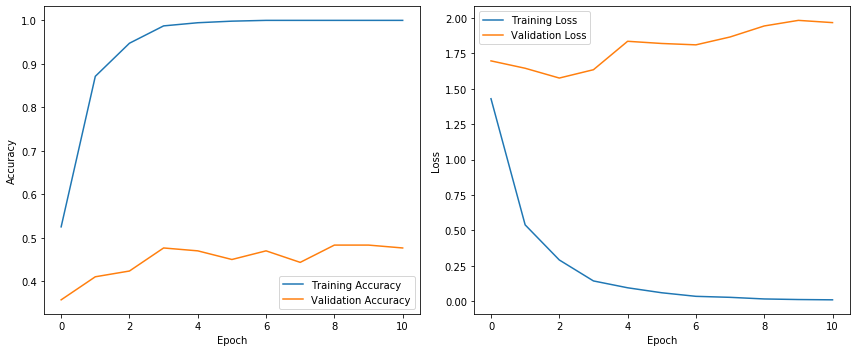

In [9]:
run_experiment(baseline_config, X, y, verbose=1, print_all=False)

### Recurrent Layer Type

| Parameter | Base model | Testing |
|---|---|---|
| Recurrent layer type | LSTM | |

**Hypothesis:** _What do you expect to happen, and why?_

**Why these values:**

**Source:** _The paper, documentation or class notes that informed your choice._

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
gru (GRU)                    (None, 256)               1771008   
_________________________________________________________________
dropout_1 (Dropout)          (None, 256)               0         
_________________________________________________________________
dense_1 (Dense)              (None, 8)                 2056      
Total params: 1,773,064
Trainable params: 1,773,064
Non-trainable params: 0
_________________________________________________________________
Train on 552 samples, validate on 151 samples
Epoch 1/100
552/552 [==============================] - 3s 5ms/sample - loss: 1.5258 - accuracy: 0.5072 - val_loss: 1.5744 - val_accuracy: 0.4570
Epoch 2/100
552/552 [==============================] - 2s 3ms/sample - loss: 0.2771 - accuracy: 0.9275 - val_loss: 1.5660 - val_accuracy: 0.5430
Epoch 3/100
552/552 [=================

Val accuracy,Val macro F1,Test Accuracy,Test Loss,Epochs run,Parameters,Latency (ms),Train time (s)
0.543046,0.545109,0.684411,0.921109,4,"Recurrent layer: GRUHidden units: 256Droupout rate: 0.5Output: (8, 'softmax')Optimizer: AdamLearning rate: 0.001Loss: sparse_categorical_crossentropyMetrics: ['accuracy']Batch size: 32Epochs: 100F1 Average: macroMoniter: val_losspatience: 8restore best weights: Truestored model name: baseline_tom.keras",17.844677,16.539880


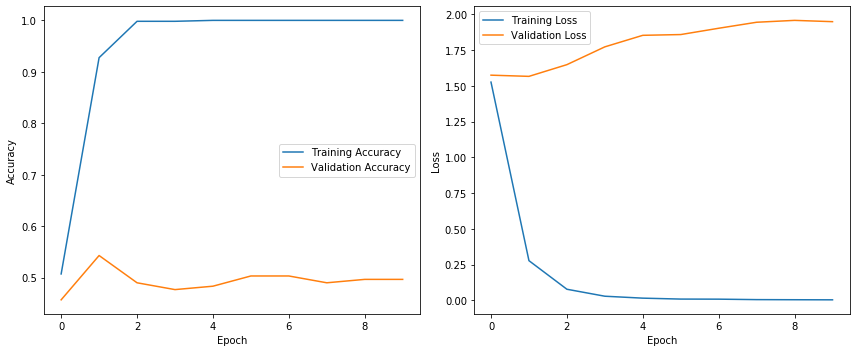

In [10]:
# here is an example of how to use the baseline
test_conf_1 = cp.deepcopy(baseline_config)
test_conf_1['Experiment Name']     = "1"
test_conf_1['Setting'] = "Recurrent Layer => GRU"
test_conf_1['Recurrent layer'] = GRU

run_experiment(test_conf_1, X, y, verbose=1, print_all=False)

In [11]:
print_report(pd.DataFrame(reports))

Run,Setting,Val accuracy,Val macro F1,Test Accuracy,Test Loss,Epochs run,Parameters,Latency (ms),Train time (s)
base,-,0.423841,0.451058,0.661597,1.020614,4,"Recurrent layer: LSTMHidden units: 256Droupout rate: 0.5Output: (8, 'softmax')Optimizer: AdamLearning rate: 0.001Loss: sparse_categorical_crossentropyMetrics: ['accuracy']Batch size: 32Epochs: 100F1 Average: macroMoniter: val_losspatience: 8restore best weights: Truestored model name: baseline_tom.keras",19.856930,22.977242
1,Recurrent Layer => GRU,0.543046,0.545109,0.684411,0.921109,4,"Recurrent layer: GRUHidden units: 256Droupout rate: 0.5Output: (8, 'softmax')Optimizer: AdamLearning rate: 0.001Loss: sparse_categorical_crossentropyMetrics: ['accuracy']Batch size: 32Epochs: 100F1 Average: macroMoniter: val_losspatience: 8restore best weights: Truestored model name: baseline_tom.keras",17.844677,16.539880


#### Results

| Run | Setting | Val accuracy | Val macro F1 | Epochs run | Params | Latency (ms) |
|---|---|---|---|---|---|---|
| Base | | | | | | |
| 1 | | | | | | |
| 2 | | | | | | |
| 3 | | | | | | |

#### Observations

_What happened? Compare each setting with the base model._

#### Insights

_Why did it turn out this way? Connect it to the dataset and to what we covered in class._

#### Conclusion

| Best value | Carry forward? | Reason |
|---|---|---|
| | | |

### Hidden Units

| Parameter | Base model | Testing |
|---|---|---|
| Hidden units | 256 | |

**Hypothesis:** _What do you expect to happen, and why?_

**Why these values:**

**Source:** _The paper, documentation or class notes that informed your choice._

#### Results

| Run | Setting | Val accuracy | Val macro F1 | Epochs run | Params | Latency (ms) |
|---|---|---|---|---|---|---|
| Base | | | | | | |
| 1 | | | | | | |
| 2 | | | | | | |
| 3 | | | | | | |

#### Observations

_What happened? Compare each setting with the base model._

#### Insights

_Why did it turn out this way? Connect it to the dataset and to what we covered in class._

#### Conclusion

| Best value | Carry forward? | Reason |
|---|---|---|
| | | |

### Number of Recurrent Layers

| Parameter | Base model | Testing |
|---|---|---|
| Number of recurrent layers | 1 | |

**Hypothesis:** _What do you expect to happen, and why?_

**Why these values:**

**Source:** _The paper, documentation or class notes that informed your choice._

#### Results

| Run | Setting | Val accuracy | Val macro F1 | Epochs run | Params | Latency (ms) |
|---|---|---|---|---|---|---|
| Base | | | | | | |
| 1 | | | | | | |
| 2 | | | | | | |
| 3 | | | | | | |

#### Observations

_What happened? Compare each setting with the base model._

#### Insights

_Why did it turn out this way? Connect it to the dataset and to what we covered in class._

#### Conclusion

| Best value | Carry forward? | Reason |
|---|---|---|
| | | |

### Summary

| Experiment | Best value | Carry forward? | Reason |
|---|---|---|---|
| Recurrent Layer Type | | | |
| Hidden Units | | | |
| Number of Recurrent Layers | | | |

#### Overall Conclusions

_What should the final model use, and what did these experiments show about the problem?_